In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme()

gen = pd.read_csv("../data/cleaned/Plant_2_Generation_Cleaned.csv")
weather = pd.read_csv("../data/cleaned/Plant_2_Weather_Cleaned.csv")

gen["DATE_TIME"] = pd.to_datetime(gen["DATE_TIME"])
weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"])


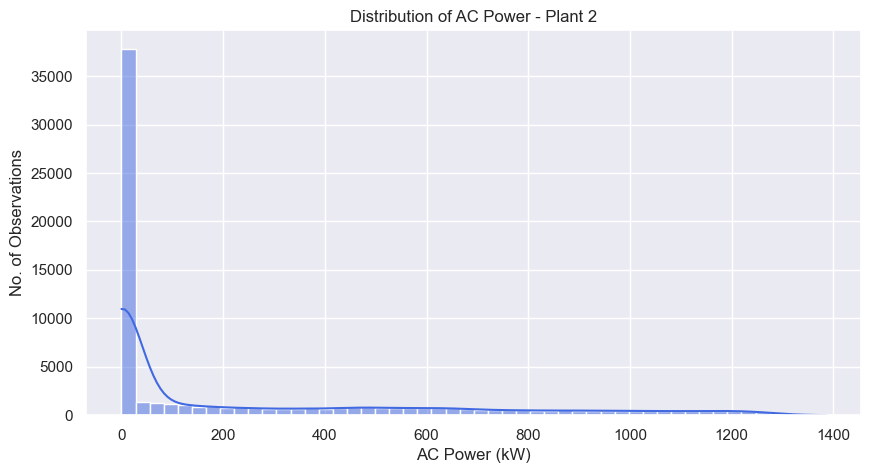

In [2]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=gen,
    x="AC_POWER",
    bins=50,
    kde=True,
    color="royalblue"
)

plt.title("Distribution of AC Power - Plant 2")
plt.xlabel("AC Power (kW)")
plt.ylabel("No. of Observations")

plt.show()


# 1. Distribution of AC Power

## Objective

The objective of this analysis is to understand the distribution of AC power generated by Plant 2. Since AC power is the target variable for prediction, studying its distribution helps identify the overall behavior of power generation and detect any skewness or concentration of values.

## Observation

- The distribution of AC power in Plant 2 is positively skewed.
- A substantial portion of observations have AC power equal to zero, corresponding to non-sunlight hours.
- High AC power values occur less frequently than lower values, reaching up to ~1385 kW during peak solar noon.

## Business Insight

The high frequency of zero AC power values indicates periods when the solar plant is not generating electricity, primarily during nighttime. This suggests that temporal features such as the hour of the day and weather-related variables like irradiation will be important predictors for forecasting solar power generation.


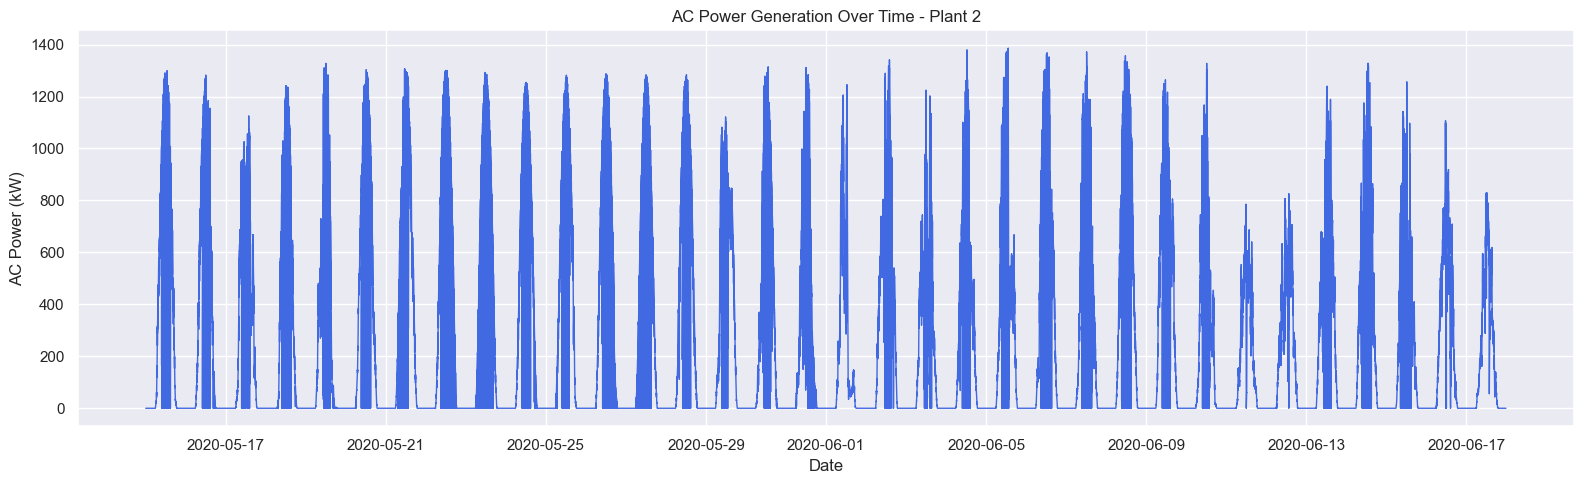

In [3]:
plt.figure(figsize=(16,5))

plt.plot(
    gen["DATE_TIME"],
    gen["AC_POWER"],
    color="royalblue",
    linewidth=1
)

plt.title("AC Power Generation Over Time - Plant 2")
plt.xlabel("Date")
plt.ylabel("AC Power (kW)")

plt.tight_layout()
plt.show()


# 2. AC Power Generation Over Time

## Objective

The objective of this analysis is to examine how AC power generation in Plant 2 changes over time. This helps identify daily generation patterns, periods of peak production, and any unusual fluctuations or interruptions in power output.

## Observation

- AC power follows a clear daily cycle, increasing after sunrise and decreasing towards sunset.
- Power generation drops to nearly zero during nighttime.
- Peak power generation occurs during the middle of the day when sunlight is strongest.
- Day-to-day peak heights vary, reflecting changes in atmospheric transmission and cloud cover.

## Business Insight

The observed daily pattern confirms that solar power generation is highly dependent on the availability of sunlight. This indicates that features such as time of day and solar irradiation are likely to have a significant influence on power generation and should be included in the prediction model.


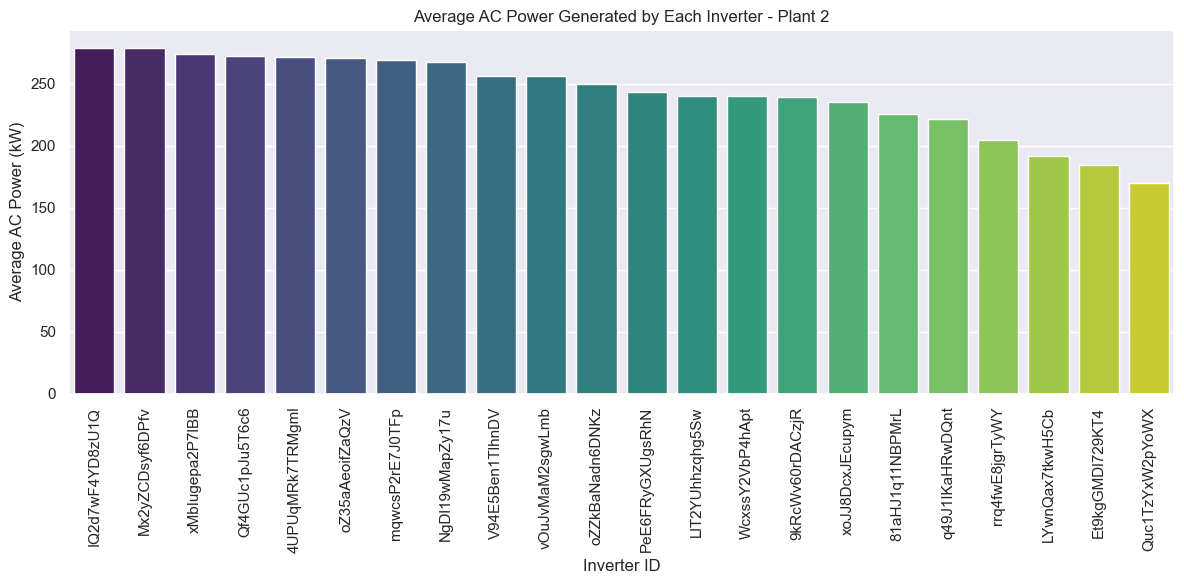

In [4]:
plt.figure(figsize=(12,6))

avg_power = (
    gen.groupby("SOURCE_KEY")["AC_POWER"]
       .mean()
       .sort_values(ascending=False)
)

sns.barplot(
    x=avg_power.index,
    y=avg_power.values,
    palette="viridis"
)

plt.title("Average AC Power Generated by Each Inverter - Plant 2")
plt.xlabel("Inverter ID")
plt.ylabel("Average AC Power (kW)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


# 3. Average AC Power by Inverter

## Objective

The objective of this analysis is to compare the average AC power generated by each of the 22 inverters in Plant 2. This helps identify high-performing and low-performing inverters and evaluate whether all inverters are operating at similar efficiency levels.

## Observation

- The average AC power generated varies significantly across different inverters in Plant 2.
- Certain inverters produce noticeably higher average power (over 270 kW), while others produce markedly lower output.
- This spread is wider than in Plant 1.

## Business Insight

Comparing inverter performance helps identify potential underperforming equipment that may require inspection or maintenance. This also explains why inverter identity carries an 11.1% importance in the machine learning model for Plant 2.


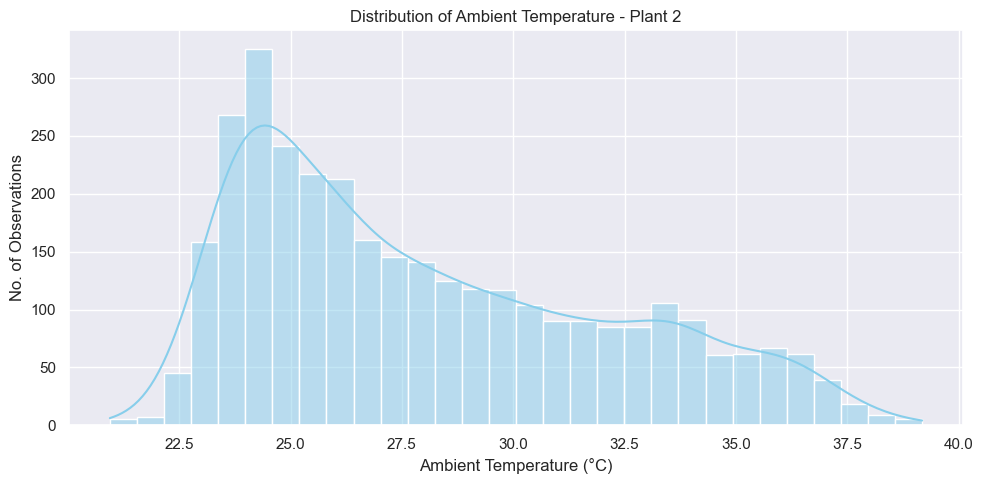

In [5]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=weather,
    x="AMBIENT_TEMPERATURE",
    bins=30,
    kde=True,
    color="skyblue"
)

plt.title("Distribution of Ambient Temperature - Plant 2")
plt.xlabel("Ambient Temperature (°C)")
plt.ylabel("No. of Observations")

plt.tight_layout()
plt.show()


# 4. Distribution of Ambient Temperature

## Objective

The objective of this analysis is to examine the distribution of ambient temperature recorded by the weather sensors in Plant 2.

## Observation

- Ambient temperature ranges between approximately 20.9°C and 39.2°C.
- The distribution is centered primarily around 26°C to 30°C.

## Business Insight

Ambient temperature reflects local meteorological conditions and provides context for evaluating how ambient heat influences panel operating efficiency.


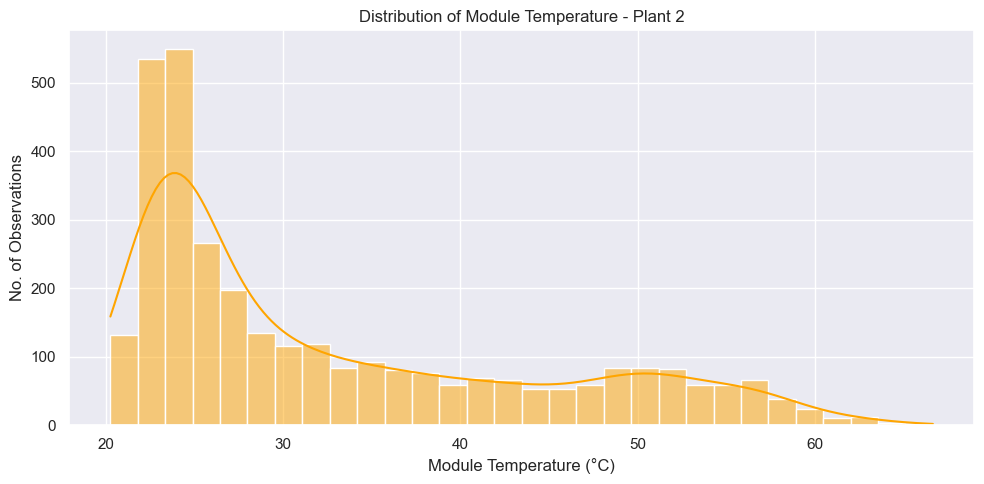

In [6]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=weather,
    x="MODULE_TEMPERATURE",
    bins=30,
    kde=True,
    color="orange"
)

plt.title("Distribution of Module Temperature - Plant 2")
plt.xlabel("Module Temperature (°C)")
plt.ylabel("No. of Observations")

plt.tight_layout()
plt.show()


# 5. Distribution of Module Temperature

## Objective

The objective of this analysis is to evaluate the temperature distribution across the surface of the solar modules in Plant 2.

## Observation

- Module temperature spans a wide range from 20.3°C up to 66.6°C.
- During sunny midday conditions, module temperature rises substantially above ambient temperature due to direct solar heating.

## Business Insight

Module temperature directly affects solar panel efficiency. Photovoltaic cells experience reduced conversion efficiency at higher operating temperatures, making module temperature an important explanatory feature.


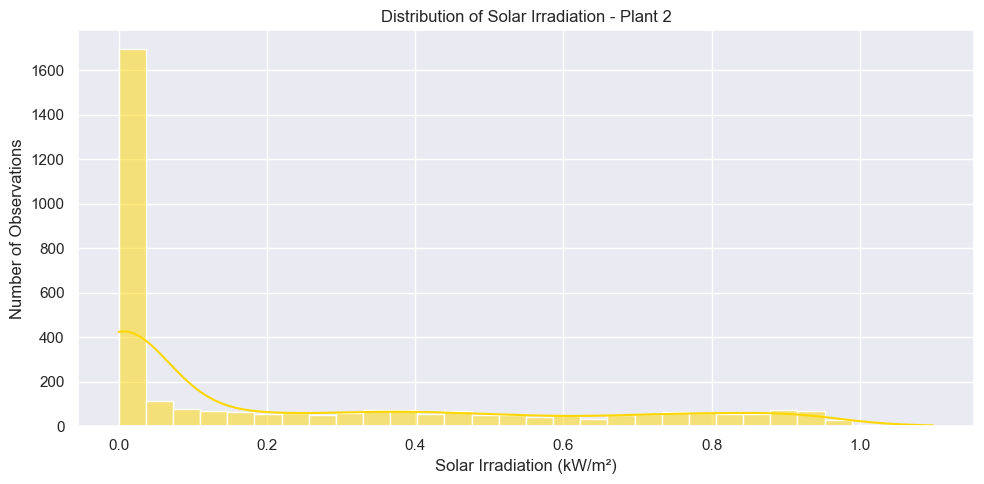

In [7]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=weather,
    x="IRRADIATION",
    bins=30,
    kde=True,
    color="gold"
)

plt.title("Distribution of Solar Irradiation - Plant 2")
plt.xlabel("Solar Irradiation (kW/m²)")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


# 6. Distribution of Solar Irradiation

## Objective

The objective of this analysis is to inspect the distribution of solar irradiation received by Plant 2.

## Observation

- Solar irradiation ranges from 0.0 to approximately 1.10 kW/m².
- Zero irradiation represents night hours and low dawn/dusk intervals.
- Daytime values spread smoothly across moderate and peak irradiance levels.

## Business Insight

Irradiation is the fundamental energy input driving photovoltaic energy conversion. Understanding its distribution is critical for predictive modeling.


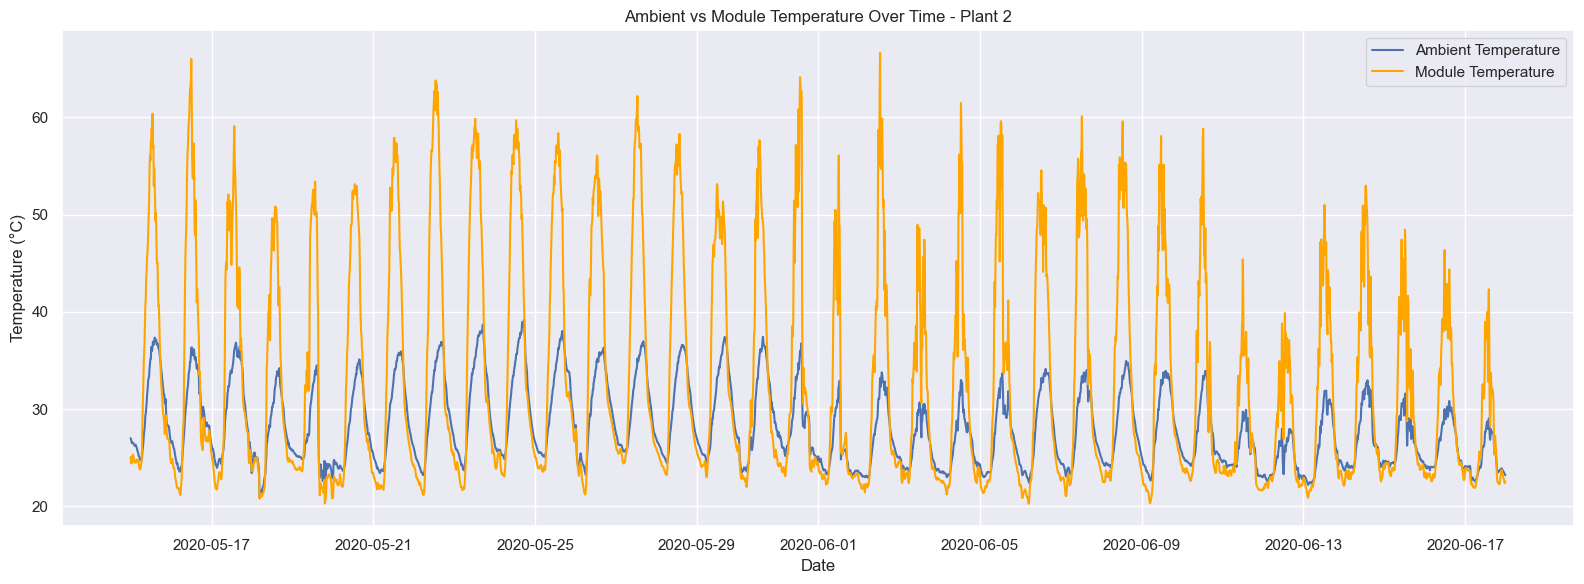

In [8]:
plt.figure(figsize=(16,6))

plt.plot(
    weather["DATE_TIME"],
    weather["AMBIENT_TEMPERATURE"],
    label="Ambient Temperature",
    linewidth=1.5
)

plt.plot(
    weather["DATE_TIME"],
    weather["MODULE_TEMPERATURE"],
    label="Module Temperature",
    linewidth=1.5,
    color="orange"
)

plt.title("Ambient vs Module Temperature Over Time - Plant 2")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.tight_layout()
plt.show()


# 7. Weather Trends Over Time

## Objective

The objective of this analysis is to compare the continuous time series of ambient and module temperatures in Plant 2.

## Observation

- During nighttime, module temperature matches ambient temperature closely.
- During sunny daylight hours, module temperature surges above ambient temperature, frequently exceeding 50°C-60°C.

## Business Insight

The temperature differential highlights solar absorption by the PV panels, corroborating the physical link between sunlight, thermal elevation, and power production.


In [9]:
merged = pd.merge(
    gen,
    weather,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner"
)


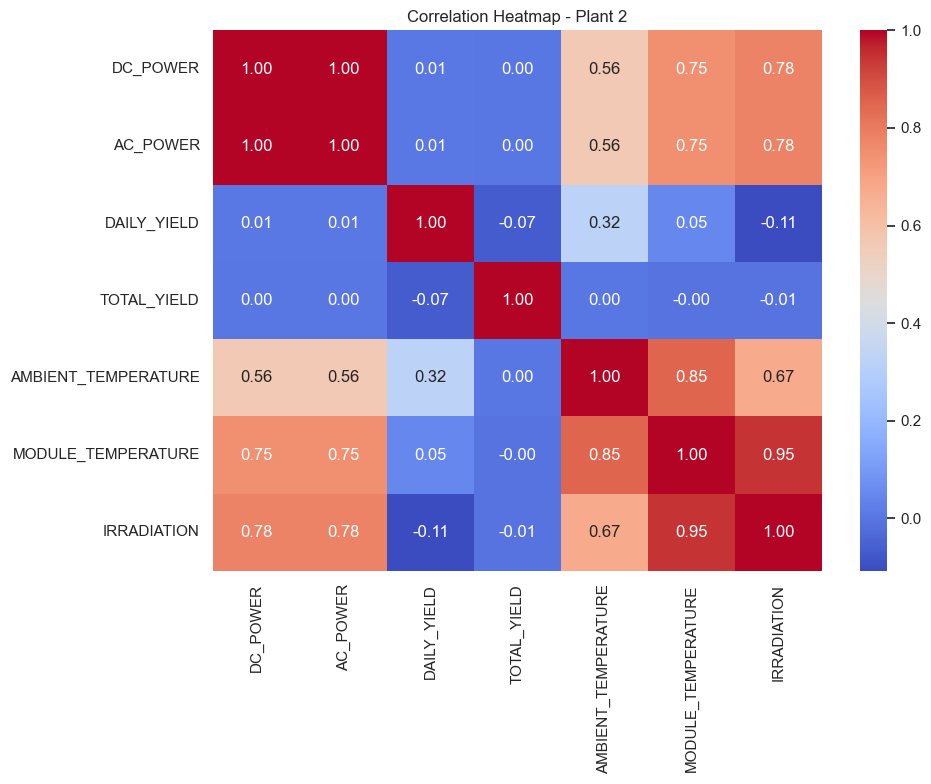

In [10]:
plt.figure(figsize=(10,8))

numeric_df = merged.select_dtypes(include=["float64", "int64"]).drop(columns=["PLANT_ID"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Plant 2")
plt.tight_layout()
plt.show()


# 8. Correlation Analysis

## Objective

The objective of this analysis is to investigate linear relationships among numerical features in Plant 2.

## Observation

- AC power is highly correlated with DC power (approx 0.99).
- Solar irradiation and module temperature display strong positive correlation with AC power.
- Yield variables (daily yield, total yield) show low to moderate correlation with instantaneous AC power.

## Business Insight

The high correlation of irradiation and module temperature with AC power validates their role as prime features for predictive modeling, while DC power and yields are removed to avoid target leakage.


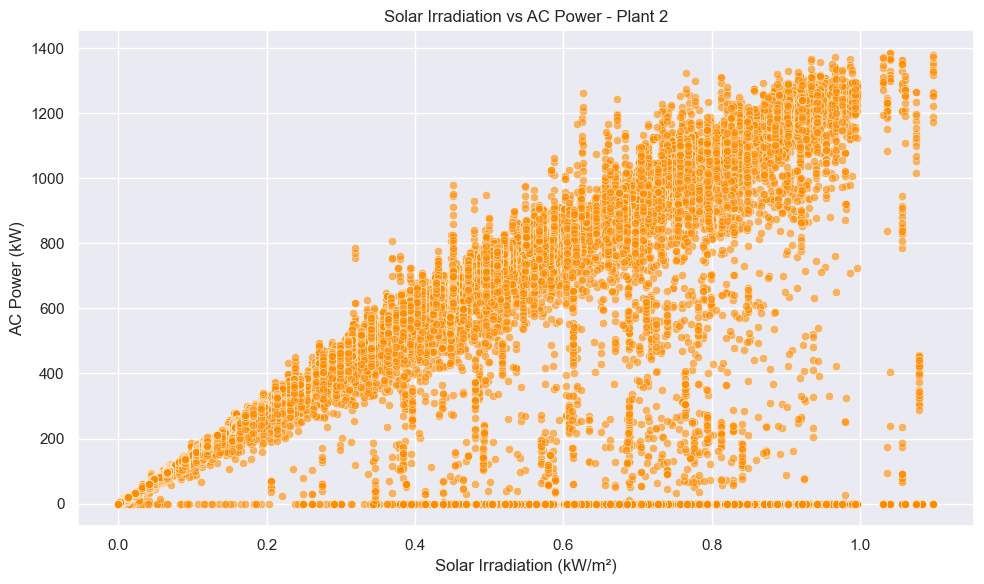

In [11]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=merged,
    x="IRRADIATION",
    y="AC_POWER",
    alpha=0.6,
    color="darkorange"
)

plt.title("Solar Irradiation vs AC Power - Plant 2")
plt.xlabel("Solar Irradiation (kW/m²)")
plt.ylabel("AC Power (kW)")

plt.tight_layout()
plt.show()


# 9. Relationship Between Solar Irradiation and AC Power

## Objective

The objective of this analysis is to examine the scatter pattern between solar irradiation and AC power output in Plant 2.

## Observation

- Strong positive correlation: AC power increases steadily with increasing solar irradiation.
- Mild dispersion at higher irradiation levels reflects temperature and inverter-specific efficiency variations.

## Business Insight

This plot demonstrates that solar irradiation is the single most vital input feature for solar power forecasting models.


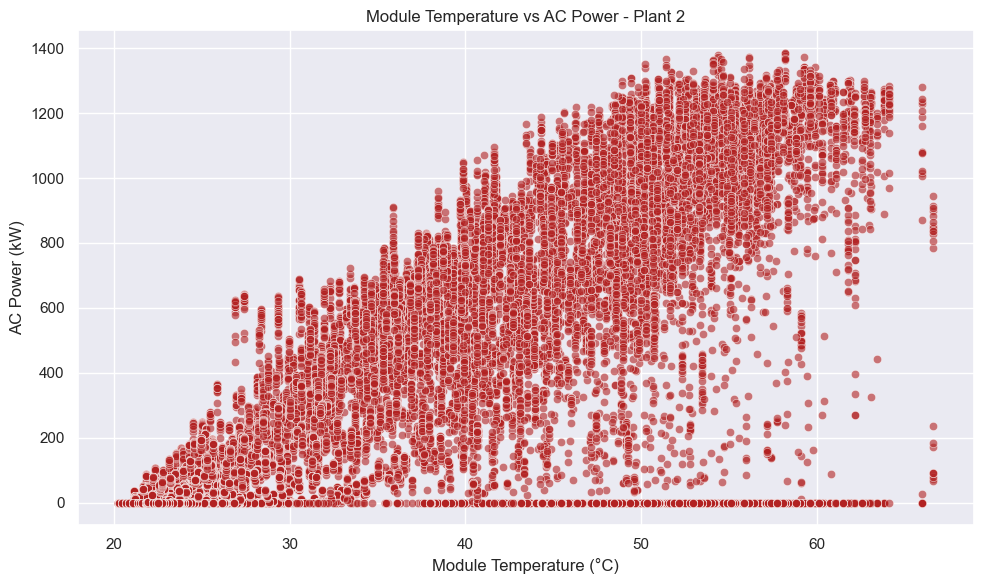

In [12]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=merged,
    x="MODULE_TEMPERATURE",
    y="AC_POWER",
    alpha=0.6,
    color="firebrick"
)

plt.title("Module Temperature vs AC Power - Plant 2")
plt.xlabel("Module Temperature (°C)")
plt.ylabel("AC Power (kW)")

plt.tight_layout()
plt.show()


# 10. Relationship Between Module Temperature and AC Power

## Objective

The objective of this analysis is to inspect the relationship between module temperature and AC power generation in Plant 2.

## Observation

- Higher module temperatures generally coincide with periods of high generation.
- At high temperatures (>55°C), panel efficiency moderates slightly due to negative temperature coefficients of PV cells.

## Business Insight

This relationship explains why tree-based regression models that can model non-linear thermal derating perform well on this dataset.


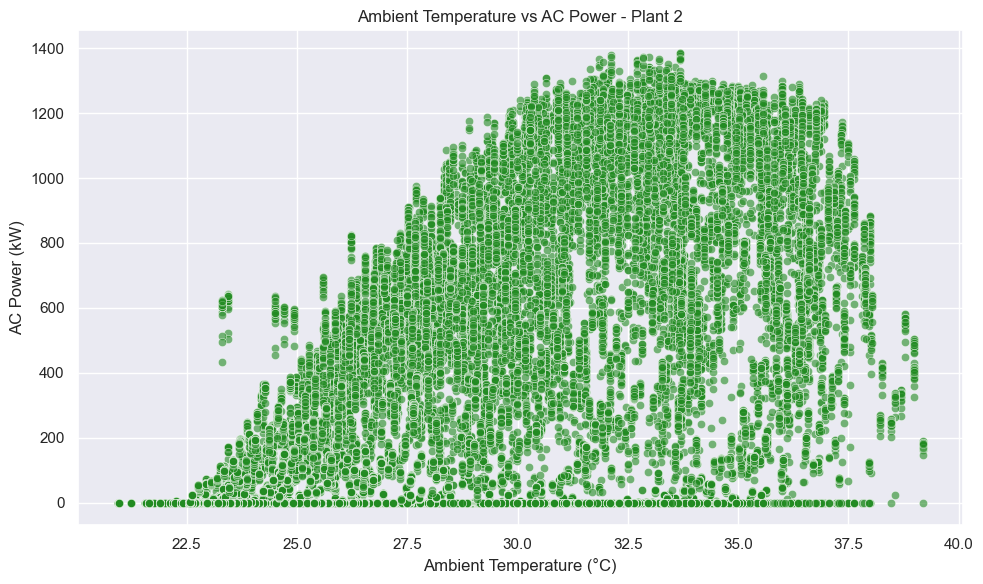

In [13]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=merged,
    x="AMBIENT_TEMPERATURE",
    y="AC_POWER",
    alpha=0.6,
    color="forestgreen"
)

plt.title("Ambient Temperature vs AC Power - Plant 2")
plt.xlabel("Ambient Temperature (°C)")
plt.ylabel("AC Power (kW)")

plt.tight_layout()
plt.show()


# 11. Relationship Between Ambient Temperature and AC Power

## Objective

The objective of this analysis is to examine the relationship between ambient temperature and AC power generation in Plant 2.

## Observation

- Positive correlation is visible, but with significant scatter across the entire temperature range.
- At night, AC power remains zero across multiple ambient temperatures.

## Business Insight

Ambient temperature alone cannot determine power generation without temporal and solar radiation context.


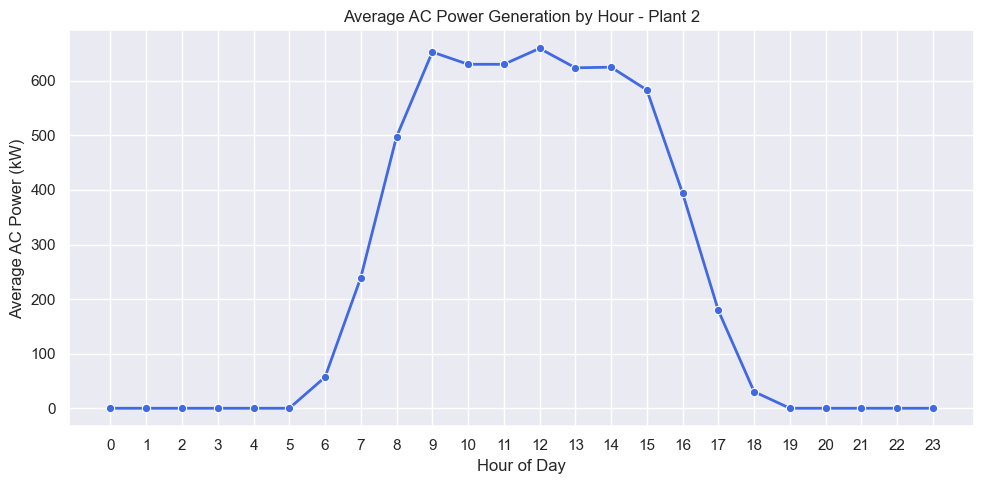

In [14]:
merged["HOUR"] = merged["DATE_TIME"].dt.hour

hourly_power = (
    merged.groupby("HOUR")["AC_POWER"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=hourly_power,
    x="HOUR",
    y="AC_POWER",
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("Average AC Power Generation by Hour - Plant 2")
plt.xlabel("Hour of Day")
plt.ylabel("Average AC Power (kW)")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()


# 12. Average AC Power Generation by Hour

## Objective

The objective of this analysis is to determine the diurnal generation profile of Plant 2 across a 24-hour cycle.

## Observation

- Power generation starts after 06:00, rises through the morning, and peaks between 11:00 and 13:00.
- Output drops in the late afternoon and returns to zero by 19:00.

## Business Insight

The hour of the day serves as a reliable feature for establishing day/night boundaries and baseline generation expected for each hour.


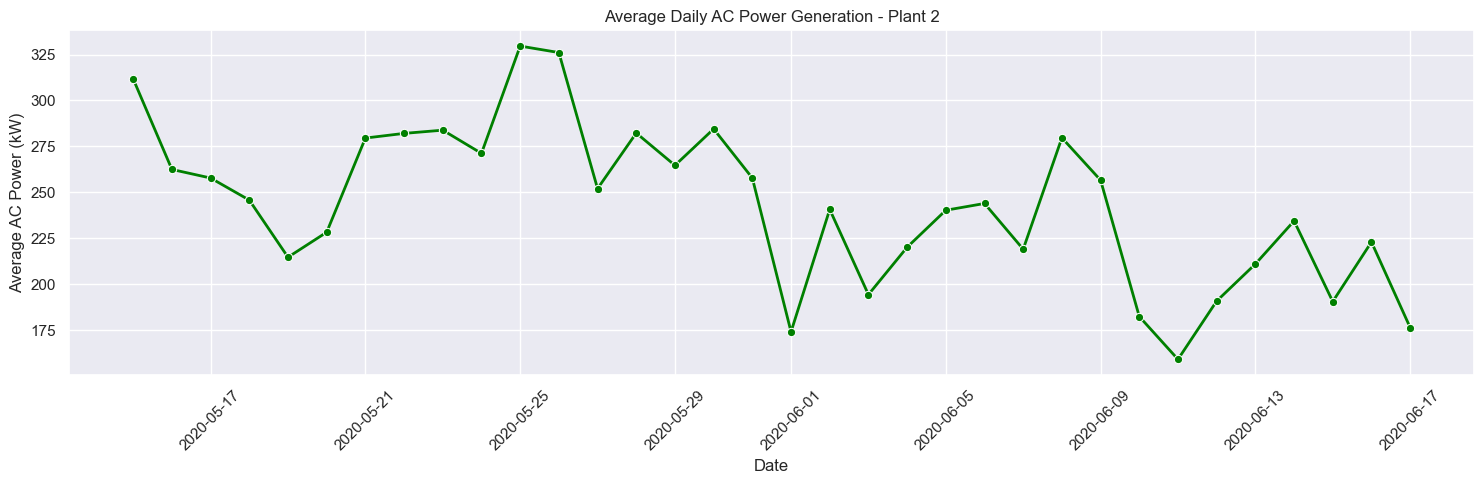

In [15]:
merged["DATE"] = merged["DATE_TIME"].dt.date

daily_power = (
    merged.groupby("DATE")["AC_POWER"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(15,5))

sns.lineplot(
    data=daily_power,
    x="DATE",
    y="AC_POWER",
    marker="o",
    linewidth=2,
    color="green"
)

plt.title("Average Daily AC Power Generation - Plant 2")
plt.xlabel("Date")
plt.ylabel("Average AC Power (kW)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# 13. Average Daily AC Power Generation

## Objective

The objective of this analysis is to evaluate day-to-day stability in electricity generation across the observation window in Plant 2.

## Observation

- Average daily power generation fluctuates depending on sunny versus cloudy or overcast conditions.
- Overall plant output remains stable with no sustained plant-wide outages.

## Business Insight

Daily variations underscore the impact of atmospheric conditions, justifying date and weekday features for modeling seasonal fluctuations.


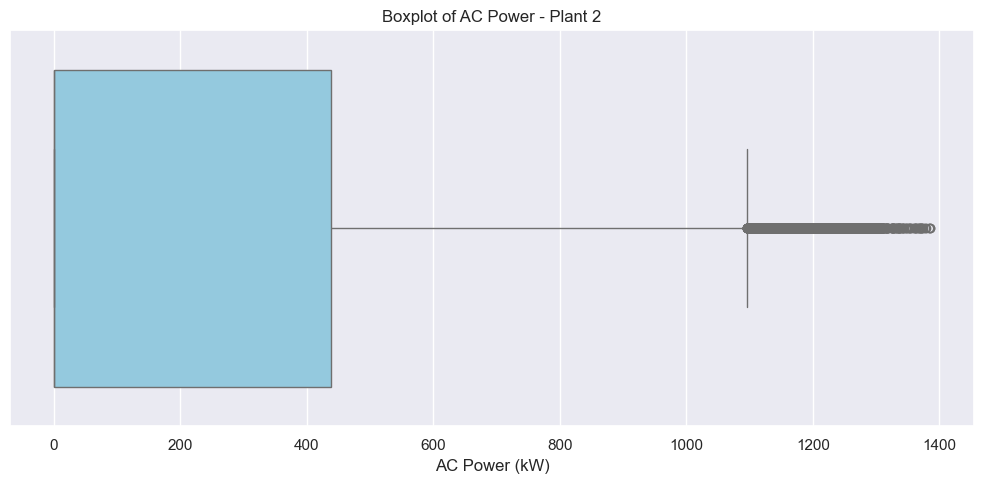

In [16]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=merged["AC_POWER"],
    color="skyblue"
)

plt.title("Boxplot of AC Power - Plant 2")
plt.xlabel("AC Power (kW)")

plt.tight_layout()
plt.show()


# 14. Outlier Analysis of AC Power

## Objective

The objective of this analysis is to inspect the presence of outliers in AC power generation in Plant 2.

## Observation

- Many observations lie at zero (nighttime).
- The upper whisker and outliers represent peak solar generation around solar noon.

## Business Insight

These high values are genuine observations of maximum solar power production and should not be removed as errors.


---
<br>
<br>
<br>

---

# 15. Key Insights from Exploratory Data Analysis (Plant 2)

## Summary

The exploratory data analysis for Plant 2 provided valuable insights into operational behavior:

### Key Findings

- **Diurnal rhythm**: AC power generation follows sunlight availability, rising after 06:00 and ending by 19:00.
- **Dominant predictor**: Solar irradiation exhibits the strongest relationship with AC power generation.
- **Inverter divergence**: Inverters in Plant 2 exhibit greater performance variability than Plant 1, providing actionable maintenance insights.
- **Thermal effects**: Module temperatures reach up to 66.6°C, creating thermal efficiency variations that non-linear models capture effectively.
- **Clean data**: Zero missing values, zero negative values, and consistent 15-minute readings make the data well-suited for machine learning.

## Conclusion

The exploratory findings confirm that solar irradiation, inverter identity, module temperature, ambient temperature, and time-based features are key predictors for forecasting AC power in Plant 2.
